# Periwinkles: rotation robustness of circular mean links

Reproduces the Blue Periwinkles rotation example from the supplement of the
*unwrap* paper (jgraving/circstats). Three otherwise-identical models are
fitted to the same 31 paired heading/distance observations - a von Mises
model on unwrap's rotation-invariant circular-modulo link, a von Mises model
on a bounded 2arctan link, and a Normal model that treats the angles as
linear - and the whole analysis is repeated after rotating every heading by
pi/2. A link that respects circular geometry gives the same science under
that arbitrary global rotation; the bounded and linear treatments do not.

Running the notebook writes four PDFs into `figures/` next to it
(plus the PNG previews embedded in the cells below).
`periwinkles_multipanel.pdf` is the published supplement figure (panels
a-d); the other three - `periwinkles_rotation_lines.pdf`,
`periwinkles_rotation_residuals.pdf`, `periwinkles_rotation_elpd.pdf` - are
its component builds and are kept for the figure's lineage.

Reproducibility: the fits use a fixed seed, 4 chains x 4 cores, and the
default draw budget; the observed R-hat / ESS / divergence numbers from the
baked run are printed by the fit cell and recorded in the PR that added this
notebook.

## 1. Fit the three models, original and rotated

`bmb.load_data("periwinkles")` ships with bambi: n = 31 field observations
of a periwinkle's heading angle paired with the straight-line distance
travelled (Fisher, 1993). The rotated frame wraps `direction + pi/2` with
the same circular-modulo response transform, so the two pipelines differ
only in the arbitrary angular origin of the response.

Bambi 0.21 no longer ships a `tan_2` von Mises link (and unwrap
deliberately does not register one), so the 2arctan adapter is built inline
exactly the way `unwrap.link.bambi` builds its own entries. All other model
specification is unchanged from the original figure code: mean direction is
modelled on `distance`, both von Mises models use the family-default
concentration link (log), the circular-modulo model additionally uses a
circular-uniform intercept prior, and every other prior (including the
2·arctan intercept) is a bambi default.

In [1]:

import numpy as np
import pandas as pd
import arviz as az
import bambi as bmb
import warnings
from pathlib import Path
from pytensor import tensor as pt

import unwrap  # noqa: F401  (registers the vonmises family for bambi)
from unwrap.link.numpy import circular_modulo
from unwrap.link.bambi import LINKS
from unwrap.prior import CircularUniformPrior

# Fixed seed so the baked posteriors - and the figures drawn from them -
# are reproducible. Everything else in the fit specification is unchanged:
# bambi's default draw budget (tune=1000, draws=1000), 4 chains x 4 cores,
# pymc's default target acceptance rate. The rotated-frame 2*arctan fit is a
# convergence knife-edge (the rotated mean angles sit near the bound of the
# bounded link): of the seeds tested (0, 1, 2, 42, 123, 1000) only 42 passes
# the gates printed below for all six fits, which is why it is pinned.
SEED = 42
CHAINS, CORES = 4, 4

# ---- data: original frame + frame rotated by pi/2 ----
data = bmb.load_data("periwinkles").copy()
data["log_distance"] = np.log1p(data["distance"])
data["direction_unshifted"] = circular_modulo(data["direction"])
data["direction_shifted"] = circular_modulo(data["direction"] + np.pi / 2)

# ---- 2*arctan mean link (bambi 0.21 dropped the old tan_2 link name) ----
# Built the same way unwrap.link.bambi builds its own registry entries:
# numpy link/linkinv plus the symbolic PyTensor backend used by the model.
def two_arctan_linkinv(eta):  # eta -> mu
    return 2 * np.arctan(eta)

def two_arctan_link(mu):  # mu -> eta
    return np.tan(mu / 2)

def two_arctan_pt(eta):  # eta -> mu (PyTensor backend)
    return 2 * pt.arctan(eta)

TWO_ARCTAN = bmb.Link(name="2arctan", link=two_arctan_link,
                      linkinv=two_arctan_linkinv,
                      linkinv_backend=two_arctan_pt)

def fit_models(df, response_col):
    """Fit the three link/likelihood models to one angular frame."""
    models, idatas = {}, {}
    specs = {
        # von Mises on unwrap's rotation-invariant circular-modulo link:
        # mu link pinned, circular-uniform intercept prior; kappa keeps
        # the family default (log).
        "vm_shifted_mod_link": dict(
            link={"mu": LINKS["circular_modulo"]},
            priors={"Intercept": CircularUniformPrior()}),
        # von Mises on the bounded 2*arctan link. As in the original
        # figure code, the intercept here keeps bambi's default prior -
        # the circular-uniform prior is used only on the circular-modulo
        # model.
        "vm_tan2": dict(
            link={"mu": TWO_ARCTAN}),
        # Normal baseline: angles treated as linear.
        "gaussian": dict(),
    }
    for name, spec in specs.items():
        kwargs = dict(family="vonmises") if name != "gaussian" else {}
        if spec.get("priors") is not None:
            kwargs["priors"] = spec["priors"]
        if spec.get("link") is not None:
            kwargs["link"] = spec["link"]
        model = bmb.Model(bmb.Formula(f"{response_col} ~ distance"), df, **kwargs)
        # log_likelihood must be in the output for the az.loo cells below.
        # Current pymc flags the idata_kwargs way of asking for it with a
        # FutureWarning; the arrays it produces are identical, so the
        # cosmetic warning is scoped out here at the source.
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message="Passing `log_likelihood` via `idata_kwargs`")
            idata = model.fit(chains=CHAINS, cores=CORES, random_seed=SEED,
                              progressbar=False, include_response_params=True,
                              idata_kwargs={"log_likelihood": True})
        models[name], idatas[name] = model, idata
    return models, idatas

models_unshifted, idatas_unshifted = fit_models(data, "direction_unshifted")
models_shifted, idatas_shifted = fit_models(data, "direction_shifted")

# ---- convergence gate (reported in the PR that ships this notebook) ----
for frame, idatas in (("original", idatas_unshifted), ("rotated", idatas_shifted)):
    for name, idata in idatas.items():
        post = idata.posterior.to_dataset()
        # Gate the identifiable quantities only: the scalar free parameters,
        # not the per-observation response parameters (include_response_params
        # adds mu, which is a deterministic function of the free params).
        free = [k for k, v in post.data_vars.items()
                if set(v.dims) <= {"chain", "draw"}]
        sub = post[free]
        r = az.rhat(sub)                        # Dataset: one scalar per param
        e = az.ess(sub, relative=False)         # bulk ESS, one scalar per param
        rvals = {k: float(v) for k, v in r.data_vars.items()}
        pname = max(rvals, key=rvals.get)
        ess_min = min(float(v) for v in e.data_vars.values())
        divs = int(idata.sample_stats["diverging"].sum())
        print(f"[gate] {frame:8s} {name:20s} rhat_max={rvals[pname]:.4f} @{pname} "
              f"ess_bulk_min={ess_min:.0f} divergences={divs}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [kappa, Intercept, distance]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


... (15 outputs left out)

Multiprocess sampling (4 chains in 4 jobs)


NUTS: [sigma, Intercept, distance]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


[gate] original vm_shifted_mod_link  rhat_max=1.0009 @distance ess_bulk_min=4207 divergences=0
[gate] original vm_tan2              rhat_max=1.0021 @Intercept ess_bulk_min=1620 divergences=0
[gate] original gaussian             rhat_max=1.0005 @sigma ess_bulk_min=4593 divergences=0
[gate] rotated  vm_shifted_mod_link  rhat_max=1.0006 @Intercept ess_bulk_min=3516 divergences=0
[gate] rotated  vm_tan2              rhat_max=1.0052 @Intercept ess_bulk_min=579 divergences=0
[gate] rotated  gaussian             rhat_max=1.0013 @Intercept ess_bulk_min=4435 divergences=0


## 2. Fitted mean direction: original vs rotated

Two rows (top: original frame, bottom: rotated frame), one column per
model. Each panel shows the model's data plus the 94% posterior HDI of the
predicted mean direction against distance; the rotated row is displayed
de-rotated by pi/2 so the panels are directly comparable. The circular-modulo
column is stable across the two rows; the other two columns shift.

In [2]:
# =========================
# Imports
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.path import Path
from matplotlib.patches import PathPatch

# for posterior arrays
import xarray as xr

# =========================
# Circular utils
# =========================
TAU = 2*np.pi

def angle_wrap(a):
    """Wrap to (-pi, pi]."""
    return (np.asarray(a) + np.pi) % TAU - np.pi

def circ_mean_from_samples(samples, axis=0):
    """Circular mean along axis (radians)."""
    return np.angle(np.mean(np.exp(1j * samples), axis=axis))

# =========================
# Circular HDI (shortest arc)
# =========================
def _circular_hdi_1d(samples, prob=0.94):
    """
    Shortest-arc HDI for one x. samples in (-pi, pi].
    Returns (lo, hi, mu) also in (-pi, pi].
    """
    samp = np.asarray(samples, float)
    samp = samp[~np.isnan(samp)]
    if samp.size == 0:
        return np.nan, np.nan, np.nan

    mu = circ_mean_from_samples(samp, axis=0)
    centered = angle_wrap(samp - mu)
    s = np.sort(centered)
    n = s.size
    if n == 1:
        a = angle_wrap(s[0] + mu)
        return a, a, angle_wrap(mu)

    m = max(1, int(np.ceil(prob * n)))  # window size (count)
    s2 = np.concatenate([s, s + TAU])
    widths = s2[m:m+n] - s2[:n]
    j = np.argmin(widths)
    lo_rel = s2[j]
    hi_rel = s2[j + m]

    lo = angle_wrap(lo_rel + mu)
    hi = angle_wrap(hi_rel + mu)
    return lo, hi, angle_wrap(mu)

def circular_hdi(samples, prob=0.94, sample_axes=("chain","draw")):
    """
    Vectorized circular HDI across x.
    samples: xarray (dims include sample_axes + 1 x dim) or numpy (C,D,X).
    Returns (lo, hi, mu) arrays of shape (X,).
    """
    if isinstance(samples, xr.DataArray):
        sample_axes = tuple(ax for ax in sample_axes if ax in samples.dims)
        xdims = [d for d in samples.dims if d not in sample_axes]
        if len(xdims) != 1:
            raise ValueError(f"Expected exactly one x dim; got {xdims} with dims={samples.dims}")
        xdim = xdims[0]
        da = samples.transpose(xdim, *sample_axes)  # (x, chain, draw)
        arr = da.stack(sample=sample_axes).values   # (X, N)
        X, _ = arr.shape
        lo = np.empty(X); hi = np.empty(X); mu = np.empty(X)
        for i in range(X):
            l, h, m = _circular_hdi_1d(arr[i, :], prob)
            lo[i], hi[i], mu[i] = l, h, m
        return lo, hi, mu

    arr = np.asarray(samples)
    if arr.ndim != 3:
        raise ValueError("Provide xarray with ('chain','draw', x) or numpy (chains, draws, X).")
    C, D, X = arr.shape
    flat = arr.reshape(C*D, X)
    lo = np.empty(X); hi = np.empty(X); mu = np.empty(X)
    for i in range(X):
        l, h, m = _circular_hdi_1d(flat[:, i], prob)
        lo[i], hi[i], mu[i] = l, h, m
    return lo, hi, mu

# =========================
# Main plotting helper
# =========================
def plot_circular_hdi(ax, x, samples, *, prob=0.9, color=None, alpha=0.15, zorder=2,
                      seam_tol=0.01, seam_pad=1):
    """
    Draw a seam-correct circular HDI band + mean line.
    - samples: xarray (chain, draw, x) or numpy (C,D,X), in radians.
    - seam_tol: gap width around ±π where the mean line is hidden (radians).
    - seam_pad: mask this many neighbors on each side of a seam point.
    Requires: circular_hdi, angle_wrap.
    """
    import numpy as np
    from matplotlib.path import Path
    from matplotlib.patches import PathPatch

    x = np.asarray(x, float)

    # 1) per-x HDI + mean
    lo, hi, mu = circular_hdi(samples, prob=prob)

    # 2) unwrap band relative to mean so top ≥ bottom, then build one polygon
    mu_u = np.unwrap(mu)
    mu_w = angle_wrap(mu)
    lo_w = angle_wrap(lo)
    hi_w = angle_wrap(hi)
    d_lo = angle_wrap(lo_w - mu_w)
    d_hi = angle_wrap(hi_w - mu_w)
    lo_u = mu_u + d_lo
    hi_u = mu_u + d_hi
    flip = (hi_u - lo_u) < 0
    hi_u[flip] += 2*np.pi

    xv = np.r_[x, x[::-1]]
    yv = np.r_[hi_u, lo_u[::-1]]
    verts = np.column_stack([xv, yv])

    # close polygon far outside Y so the closing edge is clipped away
    y_off = (hi_u.max() + lo_u.min())/2.0 + 10.0*np.pi
    x0 = x[0]
    verts = np.vstack(([x0, y_off], [x0, yv[0]], verts, [x0, yv[-1]], [x0, y_off]))

    codes = np.full(len(verts), Path.LINETO, dtype=np.uint8)
    codes[0] = Path.MOVETO
    codes[-1] = Path.CLOSEPOLY

    # 3) tile polygon in Y just enough to cover [-π, π], clip to axes
    y_min = float(min(lo_u.min(), hi_u.min()))
    y_max = float(max(lo_u.max(), hi_u.max()))
    two_pi = 2*np.pi
    k_min = int(np.ceil((-np.pi - y_max) / two_pi))
    k_max = int(np.floor(( np.pi - y_min) / two_pi))
    for k in range(k_min, k_max + 1):
        v = verts.copy()
        v[:, 1] = v[:, 1] + k * two_pi
        patch = PathPatch(
            Path(v, codes),
            facecolor=color, edgecolor="none",
            alpha=alpha, antialiased=False, zorder=zorder
        )
        patch.set_clip_path(ax.patch)
        ax.add_patch(patch)

    # 4) mean line: simply hide points near the ±π seam (no jump detection)
    mu_line = angle_wrap(mu)
    # distance to nearest seam: π - |theta|
    dist_to_seam = np.pi - np.abs(mu_line)
    mask = dist_to_seam < seam_tol
    if seam_pad and np.any(mask):
        idx = np.where(mask)[0]
        for i in idx:
            a = max(0, i - seam_pad)
            b = min(len(mu_line), i + seam_pad + 1)
            mask[a:b] = True
    mu_line_masked = mu_line.copy()
    mu_line_masked[mask] = np.nan
    ax.plot(x, mu_line_masked, lw=2, color=color, zorder=zorder+1)

    # 5) pretty y axis
    ax.set_ylim(-np.pi, np.pi)
    ax.set_yticks([-np.pi, 0, np.pi], labels=[r"$-\pi$", "0", r"$\pi$"])

    return lo_w, hi_w, mu_w

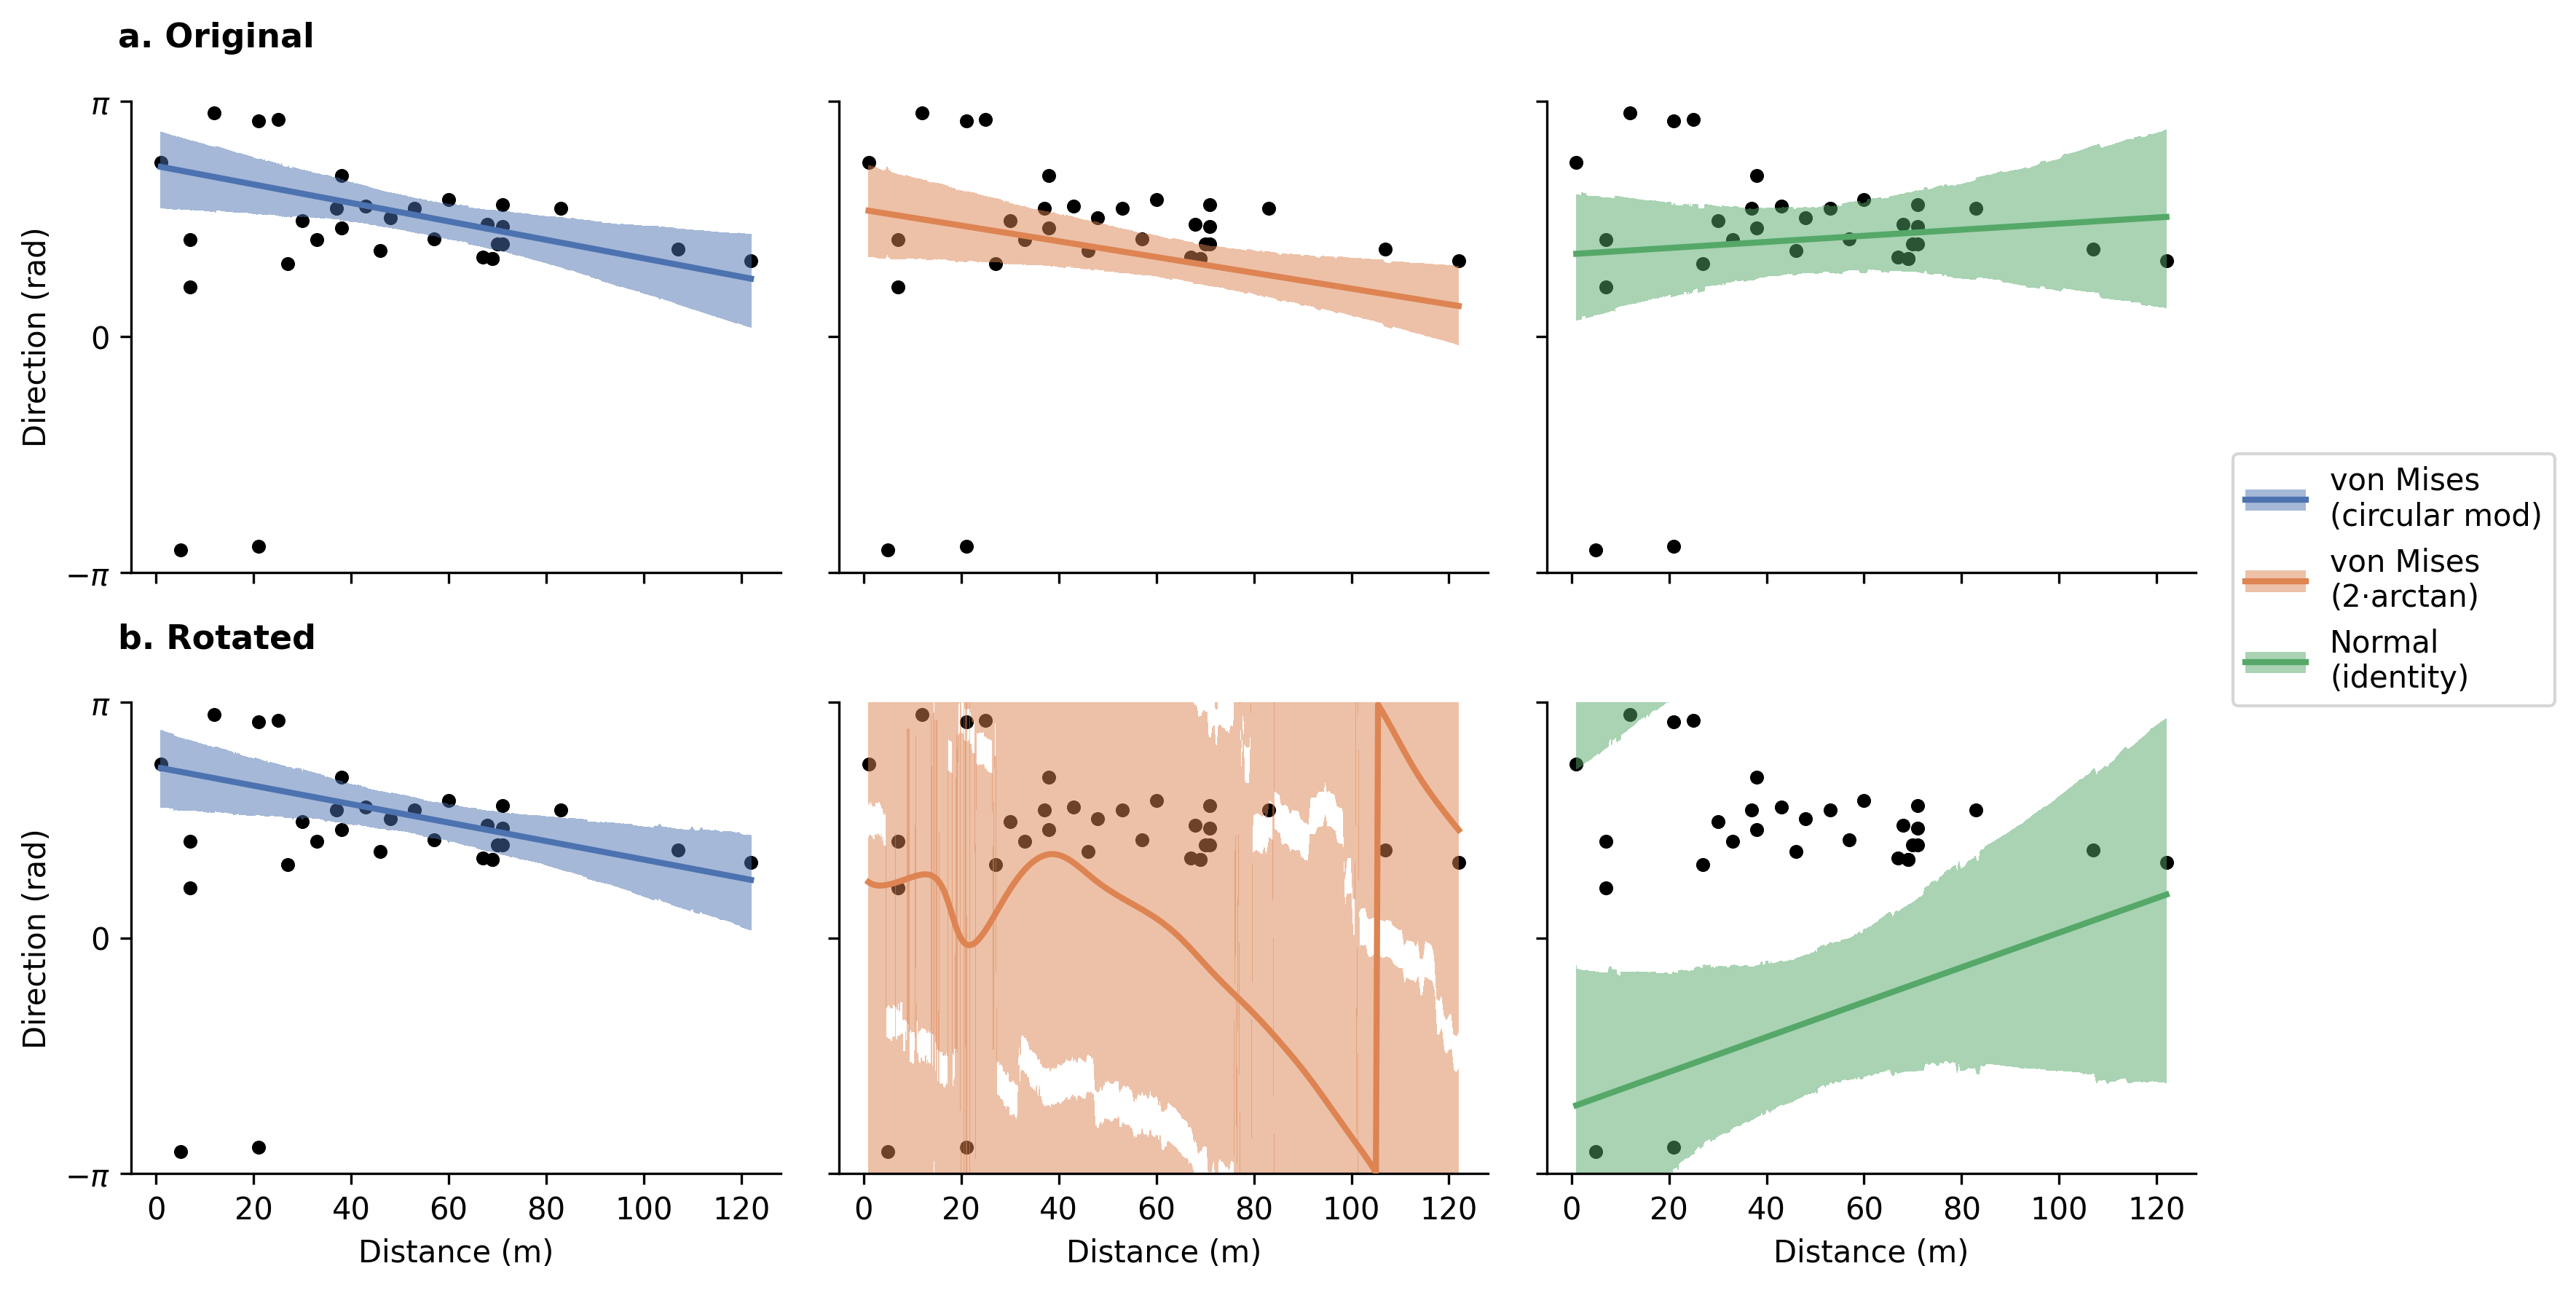

In [3]:
from pathlib import Path
# --- Cell 2: two-row plot (with shared legend) ---

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple

# palette + figure
palette = sns.color_palette("deep", 3)
fig, ax = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)

# prediction grid (log space -> back to meters)
log_dist_grid = np.linspace(data.log_distance.min(), data.log_distance.max(), 1000)
dist_grid = np.expm1(log_dist_grid)
grid_df = pd.DataFrame({"distance": dist_grid, "log_distance": log_dist_grid})

def _plot_row(ax_row, *, models, idatas, scatter_y, deshift=0.0, row_title=""):
    # 1) von Mises (shifted modulo link)
    c0 = palette[0]
    pred = models["vm_shifted_mod_link"].predict(idata=idatas["vm_shifted_mod_link"], data=grid_df, inplace=False)
    post0 = angle_wrap(pred.posterior["mu"] - deshift)
    plot_circular_hdi(ax_row[0], dist_grid, post0, prob=0.94, color=c0, alpha=0.5)
    sns.scatterplot(x=data.distance, y=angle_wrap(scatter_y - deshift),
                    ax=ax_row[0], s=18, color="black", edgecolor=None, alpha=1.0)

    # 2) von Mises (2·arctan link)
    c1 = palette[1]
    pred = models["vm_tan2"].predict(idata=idatas["vm_tan2"], data=grid_df, inplace=False)
    post1 = angle_wrap(pred.posterior["mu"] - deshift)
    plot_circular_hdi(ax_row[1], dist_grid, post1, prob=0.94, color=c1, alpha=0.5)
    sns.scatterplot(x=data.distance, y=angle_wrap(scatter_y - deshift),
                    ax=ax_row[1], s=18, color="black", edgecolor=None, alpha=1.0)

    # 3) Normal baseline
    c2 = palette[2]
    pred = models["gaussian"].predict(idata=idatas["gaussian"], data=grid_df, inplace=False)
    post2 = angle_wrap(pred.posterior["mu"] - deshift)
    plot_circular_hdi(ax_row[2], dist_grid, post2, prob=0.94, color=c2, alpha=0.5)
    sns.scatterplot(x=data.distance, y=angle_wrap(scatter_y - deshift),
                    ax=ax_row[2], s=18, color="black", edgecolor=None, alpha=1.0)

    for a in ax_row:
        a.set_xlabel("Distance (m)")
    ax_row[0].set_ylabel("Direction (rad)")
    if row_title:
        ax_row[0].text(-0.02, 1.10, row_title, transform=ax_row[0].transAxes,
                       ha="left", va="bottom", fontsize=11, weight="bold")

# TOP: unshifted data/models (no deshift)
_plot_row(
    ax[0],
    models=models_unshifted,
    idatas=idatas_unshifted,
    scatter_y=data["direction_unshifted"].to_numpy(),
    deshift=0.0,
    row_title="a. Original"
)

# BOTTOM: shifted data/models, de-shifted for display by π/2
_plot_row(
    ax[1],
    models=models_shifted,
    idatas=idatas_shifted,
    scatter_y=data["direction_shifted"].to_numpy(),
    deshift=np.pi/2,
    row_title="b. Rotated"
)

for j in range(3):
    ax[1, j].set_xlabel("Distance (m)")
for j in range(3):
    ax[0, j].set_xlabel("")

# --- shared legend to the right: line on top of fill inside each key ---
from matplotlib.legend_handler import HandlerBase
from matplotlib.patches import Rectangle

class HandlerLineOnFill(HandlerBase):
    def create_artists(self, legend, orig_handle,
                       xdescent, ydescent, width, height, fontsize, trans):
        color, alpha, lw = orig_handle  # packed payload
        # draw fill box
        rect = Rectangle((xdescent, ydescent), width, height,
                         transform=trans, facecolor=color, edgecolor='none', alpha=alpha)
        # draw line centered and on top
        y = ydescent + height / 2.0
        line = Line2D([xdescent, xdescent + width], [y, y],
                      transform=trans, color=color, lw=lw)
        return [rect, line]

labels = ["von Mises\n(circular mod)", "von Mises\n(2·arctan)", "Normal\n(identity)"]
colors = [palette[0], palette[1], palette[2]]

# pack (color, alpha, lw) so the handler can render each key
handles = [(c, 0.5, 2) for c in colors]

leg = fig.legend(
    handles, labels,
    handler_map={tuple: HandlerLineOnFill()},
    loc="center left", bbox_to_anchor=(0.85, 0.55),
    frameon=True, title=""
)
sns.despine()
fig.set(dpi=300)

# leave room on the right for the legend without squishing subplots
# (adjust if your legend width changes)
fig.tight_layout(rect=[0, 0, 0.86, 1])
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/periwinkles_rotation_lines.png", dpi=300, bbox_inches="tight")
plt.savefig("figures/periwinkles_rotation_lines.pdf", bbox_inches="tight")
plt.show()

In [4]:
import numpy as np
import xarray as xr

# ---------------- helpers ----------------
def wrap_circ(x):
    """Wrap angles to (-pi, pi]."""
    return np.arctan2(np.sin(x), np.cos(x))

def xr_circmean(da, dim, period=2*np.pi, center=0.0):
    """
    Circular mean of `da` along `dim` via vector averaging.
    Works with dask-backed DataArrays.
    """
    shifted = da - center
    s = xr.apply_ufunc(np.sin, shifted, dask="vectorized", output_dtypes=[float]).mean(dim)
    c = xr.apply_ufunc(np.cos, shifted, dask="vectorized", output_dtypes=[float]).mean(dim)
    mean_angle = xr.apply_ufunc(np.arctan2, s, c, dask="vectorized", output_dtypes=[float])
    return mean_angle + center

def infer_obs_dim(mu_da, n_obs):
    """
    Guess the observation dimension by matching length.
    Falls back to the last non-(chain/draw) dim; if none, the last dim.
    """
    # exact match first
    for d in mu_da.dims:
        if d not in ("chain", "draw") and mu_da.sizes[d] == n_obs:
            return d
    # otherwise prefer a non-sample dim
    non_sample_dims = [d for d in mu_da.dims if d not in ("chain", "draw")]
    if non_sample_dims:
        return non_sample_dims[-1]
    # final fallback
    return mu_da.dims[-1]

def posterior_bias_per_draw(y_obs, mu_da):
    """
    Posterior distribution of mean residual bias (in radians).

    Steps:
      - Align observed y to mu's observation dimension.
      - residuals = wrap_circ(y - mu) for every posterior (chain, draw).
      - circular mean over observations -> bias per (chain, draw).
      - return stacked 1D numpy array of samples.
    """
    y_obs = np.asarray(y_obs)
    obs_dim = infer_obs_dim(mu_da, len(y_obs))
    y = xr.DataArray(y_obs, dims=[obs_dim])

    # residuals broadcast over (chain, draw, obs_dim)
    res = wrap_circ(y - mu_da)

    # circular mean over observations
    bias = xr_circmean(res, dim=obs_dim)

    # stack to 1D vector of samples
    if "chain" in bias.dims and "draw" in bias.dims:
        bias = bias.stack(sample=("chain", "draw"))
    elif "draw" in bias.dims:
        bias = bias.rename({"draw": "sample"})
    elif "chain" in bias.dims:
        bias = bias.rename({"chain": "sample"})
    return np.asarray(bias)

## 3. Posterior residual bias

For every posterior draw and each model, the circular mean of the residuals
(observed angle minus predicted mean direction) - the models' systematic
bias - shown for the original and rotated pipelines side by side. The
circular-modulo bias stays centred on zero in both frames; the bounded and
linear treatments drift when the origin rotates.

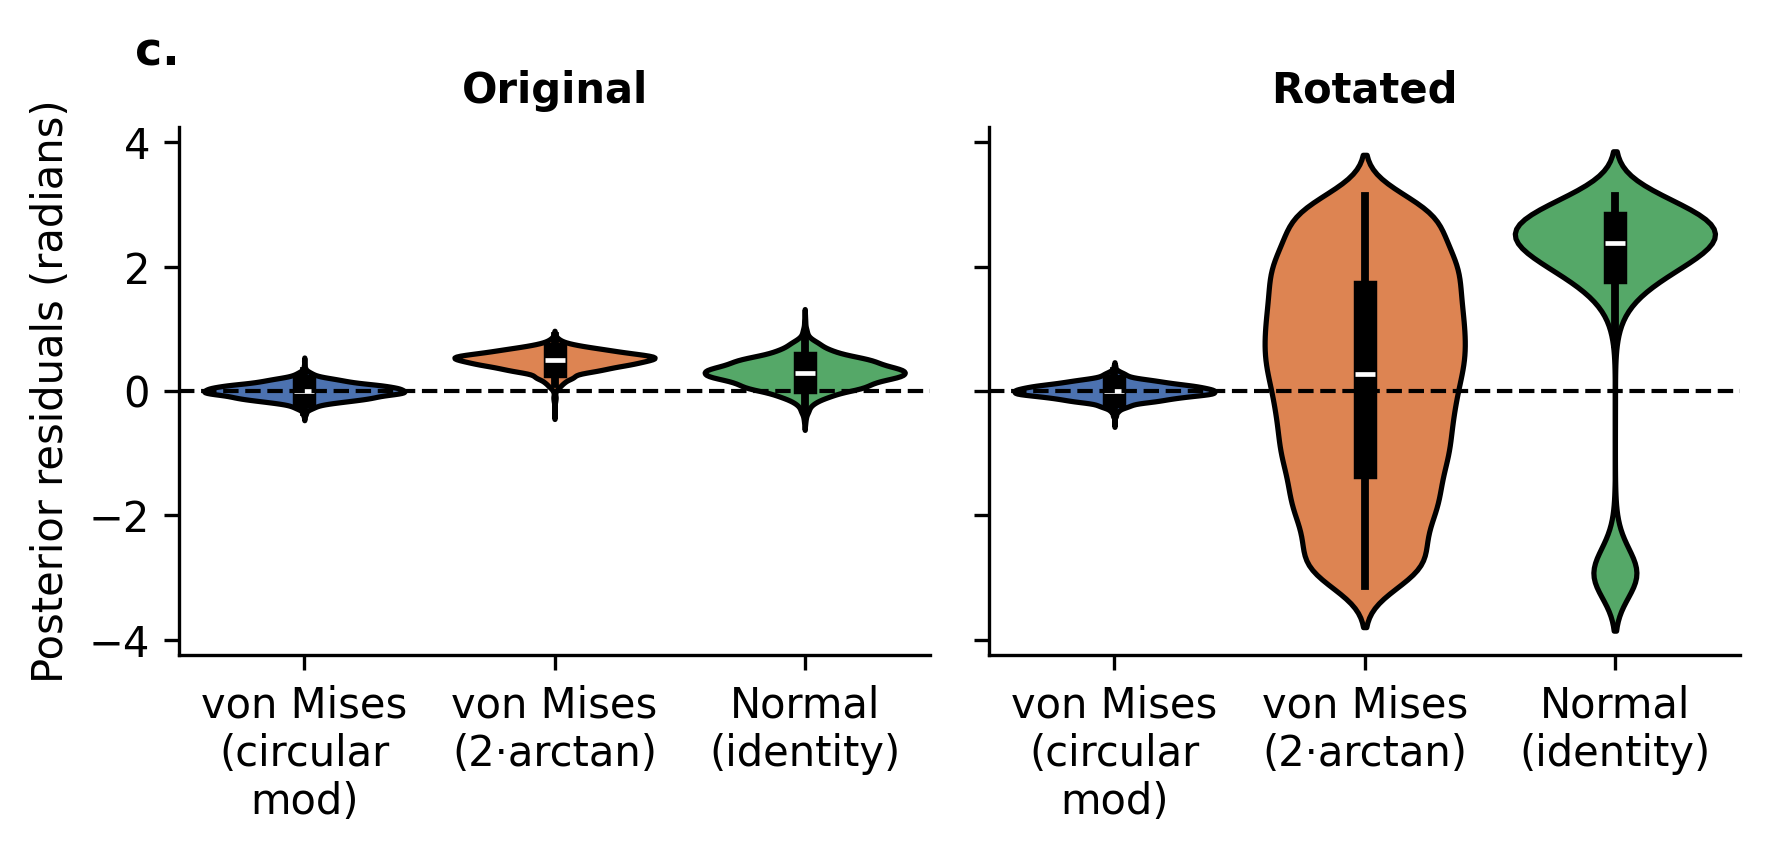

In [5]:
from pathlib import Path
# --- Cell: posterior residual bias • original vs shifted side-by-side ---

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import xarray as xr

# Labels (same 3 models as before)
labels = ["von Mises\n(circular\nmod)", "von Mises\n(2·arctan)", "Normal\n(identity)"]
# colors
palette = sns.color_palette("deep", 3)
c0, c1, c2 = palette
violin_palette = {
    "von Mises\n(circular\nmod)": c0,
    "von Mises\n(2·arctan)":       c1,
    "Normal\n(identity)":                      c2,
}

def biases_from_idatas(idatas, y_obs, deshift_mu_by=0.0):
    """
    Build bias arrays for the 3 models in one preprocessing.
    If deshift_mu_by!=0, subtract that value from mu before computing residuals
    so residuals are evaluated in the original (unshifted) frame.
    """
    out = {}
    # map keys in your idatas dict to pretty labels
    key2label = {
        "vm_shifted_mod_link": "von Mises\n(circular\nmod)",
        "vm_tan2":             "von Mises\n(2·arctan)",
        "gaussian":            "Normal\n(identity)",
    }
    for key, label in key2label.items():
        mu = idatas[key].posterior["mu"]
        if deshift_mu_by != 0.0:
            # shift means back so residuals compare to unshifted y
            mu = mu - deshift_mu_by
        out[label] = posterior_bias_per_draw(y_obs, mu)
    return out

# ---------- compute biases ----------
# LEFT PANEL: models trained on UNshifted data, compare to unshifted y
bias_left = biases_from_idatas(
    idatas_unshifted,
    y_obs=np.asarray(data["direction_unshifted"]),
    deshift_mu_by=0.0
)

# RIGHT PANEL: models trained on SHIFTED data, but de-shift mu by π/2
# then compare to unshifted y so frames match
bias_right = biases_from_idatas(
    idatas_shifted,
    y_obs=np.asarray(data["direction_unshifted"]),
    deshift_mu_by=np.pi/2
)

# ---------- pack tidy data ----------
def to_df(bias_dict, pipeline_label):
    return pd.DataFrame({
        "bias": np.concatenate([bias_dict[labels[0]], bias_dict[labels[1]], bias_dict[labels[2]]]),
        "model": ([labels[0]] * len(bias_dict[labels[0]])
                 +[labels[1]] * len(bias_dict[labels[1]])
                 +[labels[2]] * len(bias_dict[labels[2]])),
        "pipeline": pipeline_label,
    })

df_left  = to_df(bias_left,  "Original")
df_right = to_df(bias_right, "Rotated")
df = pd.concat([df_left, df_right], ignore_index=True)

# ---------- plot side-by-side ----------
fig, axes = plt.subplots(1, 2, figsize=(6, 3), sharey=True)

for ax, pipe in zip(axes, ["Original", "Rotated"]):
    dfp = df[df["pipeline"] == pipe]
    sns.violinplot(
        data=dfp, x="model", y="bias",
        order=labels, ax=ax, hue="model", legend=False,
        palette=violin_palette,
        saturation=1, alpha=1.0,
        linecolor="k",
        inner_kws={"color": "k"}
    )
    ax.axhline(0, ls="--", lw=1, color="k")
    ax.set_xlabel("")
    ax.set_title(pipe, fontsize=10, weight="bold")

axes[0].set_ylabel("Posterior residuals (radians)")
axes[1].set_ylabel("")
axes[0].text(0.0, 1.10, "c.", transform=axes[0].transAxes,
               ha="right", va="bottom", fontsize=11, weight="bold")

sns.despine()
fig.set(dpi=300)
plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/periwinkles_rotation_residuals.png", dpi=300, bbox_inches="tight")
plt.savefig("figures/periwinkles_rotation_residuals.pdf", bbox_inches="tight")

plt.show()

## 4. Pointwise expected log predictive density (PSIS-LOO)

Per-observation ELPD from `az.loo` for each model, again original vs
rotated. The statistical k-hat warning from arviz, when it fires, is a
diagnostic about the LOO approximation for this small dataset and is kept in
the output on purpose.

/home/jake/.venvs/unwrap-env/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/jake/.venvs/unwrap-env/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


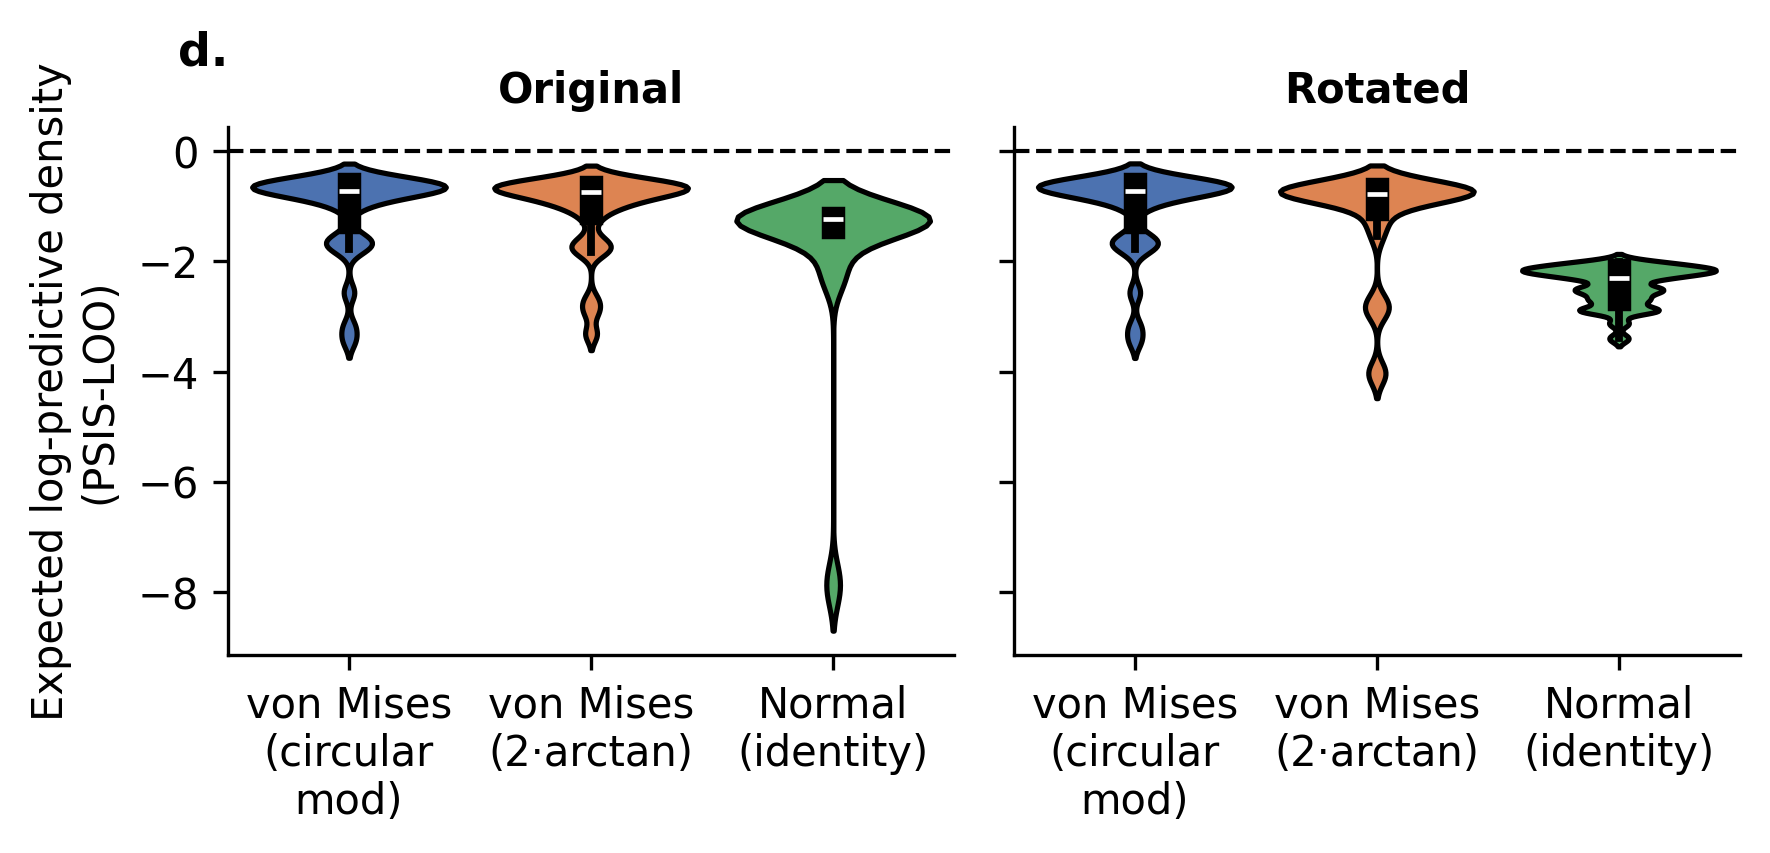

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import arviz as az

# --- colors (reuse if already defined) ---
try:
    c0, c1, c2  # noqa: F823
except NameError:
    palette = sns.color_palette("deep", 3)
    c0, c1, c2 = palette

# --- pointwise ELPD helper (handles ArviZ versions) ---
def pointwise_elpd(idata):
    # arviz's internal exp() overflows harmlessly on the PSIS path;
    # only the numerical warning is suppressed, the statistical k-hat
    # UserWarning is kept.
    with np.errstate(over="ignore"):
        loo = az.loo(idata, pointwise=True)
    if hasattr(loo, "elpd_i"):
        arr = loo.elpd_i
    elif hasattr(loo, "loo_i"):
        arr = loo.loo_i
    else:
        raise AttributeError("Could not find pointwise ELPD in az.loo result.")
    return np.asarray(arr)

# Model label order (consistent across both panels)
labels_loo = ["von Mises\n(circular\nmod)", "von Mises\n(2·arctan)", "Normal\n(identity)"]

# Palette keyed to labels
violin_palette_loo = {
    labels_loo[0]: c0,
    labels_loo[1]: c1,
    labels_loo[2]: c2,
}

# --- helper to build a tidy df for one pipeline (a dict of idatas) ---
def elpd_df_for_pipeline(idatas_dict, pipeline_name):
    key2label = {
        "vm_shifted_mod_link": labels_loo[0],
        "vm_tan2":             labels_loo[1],
        "gaussian":            labels_loo[2],
    }
    arrays = []
    names = []
    for key, label in key2label.items():
        elpd_i = pointwise_elpd(idatas_dict[key])
        arrays.append(elpd_i)
        names.extend([label] * len(elpd_i))
    df = pd.DataFrame({
        "elpd_i": np.concatenate(arrays),  # back to density scale like your original
        "model": names,
        "pipeline": pipeline_name,
    })
    return df

# Build data for both: left = original/unshifted, right = shifted
df_left  = elpd_df_for_pipeline(idatas_unshifted, "Original")
df_right = elpd_df_for_pipeline(idatas_shifted,   "Rotated")
df_both = pd.concat([df_left, df_right], ignore_index=True)

# --- plot side-by-side ---
fig, axes = plt.subplots(1, 2, figsize=(6, 3), sharey=True)

for ax, pname in zip(axes, ["Original", "Rotated"]):
    d = df_both[df_both["pipeline"] == pname]
    sns.violinplot(
        data=d, x="model", y="elpd_i",
        order=labels_loo, ax=ax, hue="model", legend=False,
        palette=violin_palette_loo,
        saturation=1, alpha=1.0,
        linecolor="k",
        inner_kws={"color": "k"},
        bw_method=0.2
    )
    # Optional: mark mean
    # means = d.groupby("model", sort=False)["elpd_i"].mean().reindex(labels_loo)
    # ax.scatter(range(len(labels_loo)), means.values, s=30, zorder=3,
    #            edgecolor="k", facecolor="white", linewidth=0.8)

    ax.axhline(0, ls="--", lw=1, color="k")
    ax.set_xlabel("")
    ax.set_title(pname, fontsize=10, weight="bold")

axes[0].set_ylabel("Expected log-predictive density\n(PSIS-LOO)")
axes[1].set_ylabel("")
# Keep a consistent y-range if you want direct visual comparability:
# axes[0].set_ylim(0, 0.7); axes[1].set_ylim(0, 0.7)
axes[0].text(0.0, 1.10, "d.", transform=axes[0].transAxes,
               ha="right", va="bottom", fontsize=11, weight="bold")

sns.despine()
fig.set(dpi=300)
plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/periwinkles_rotation_elpd.png", dpi=300, bbox_inches="tight")
plt.savefig("figures/periwinkles_rotation_elpd.pdf", bbox_inches="tight")
plt.show()

## 5. The published multi-panel figure

The self-contained cell below rebuilds the supplement figure in one figure:
(a)/(b) the fitted-means rows from section 2, (c) the residual-bias violins
from section 3, (d) the ELPD difference from the best model in each frame
with its standard error. It redefines its helpers so it can be run on its
own from the fitted objects in cell 1. Saved as `figures/periwinkles_multipanel.pdf`
(transparent background, paper layout).

/home/jake/.venvs/unwrap-env/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/jake/.venvs/unwrap-env/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


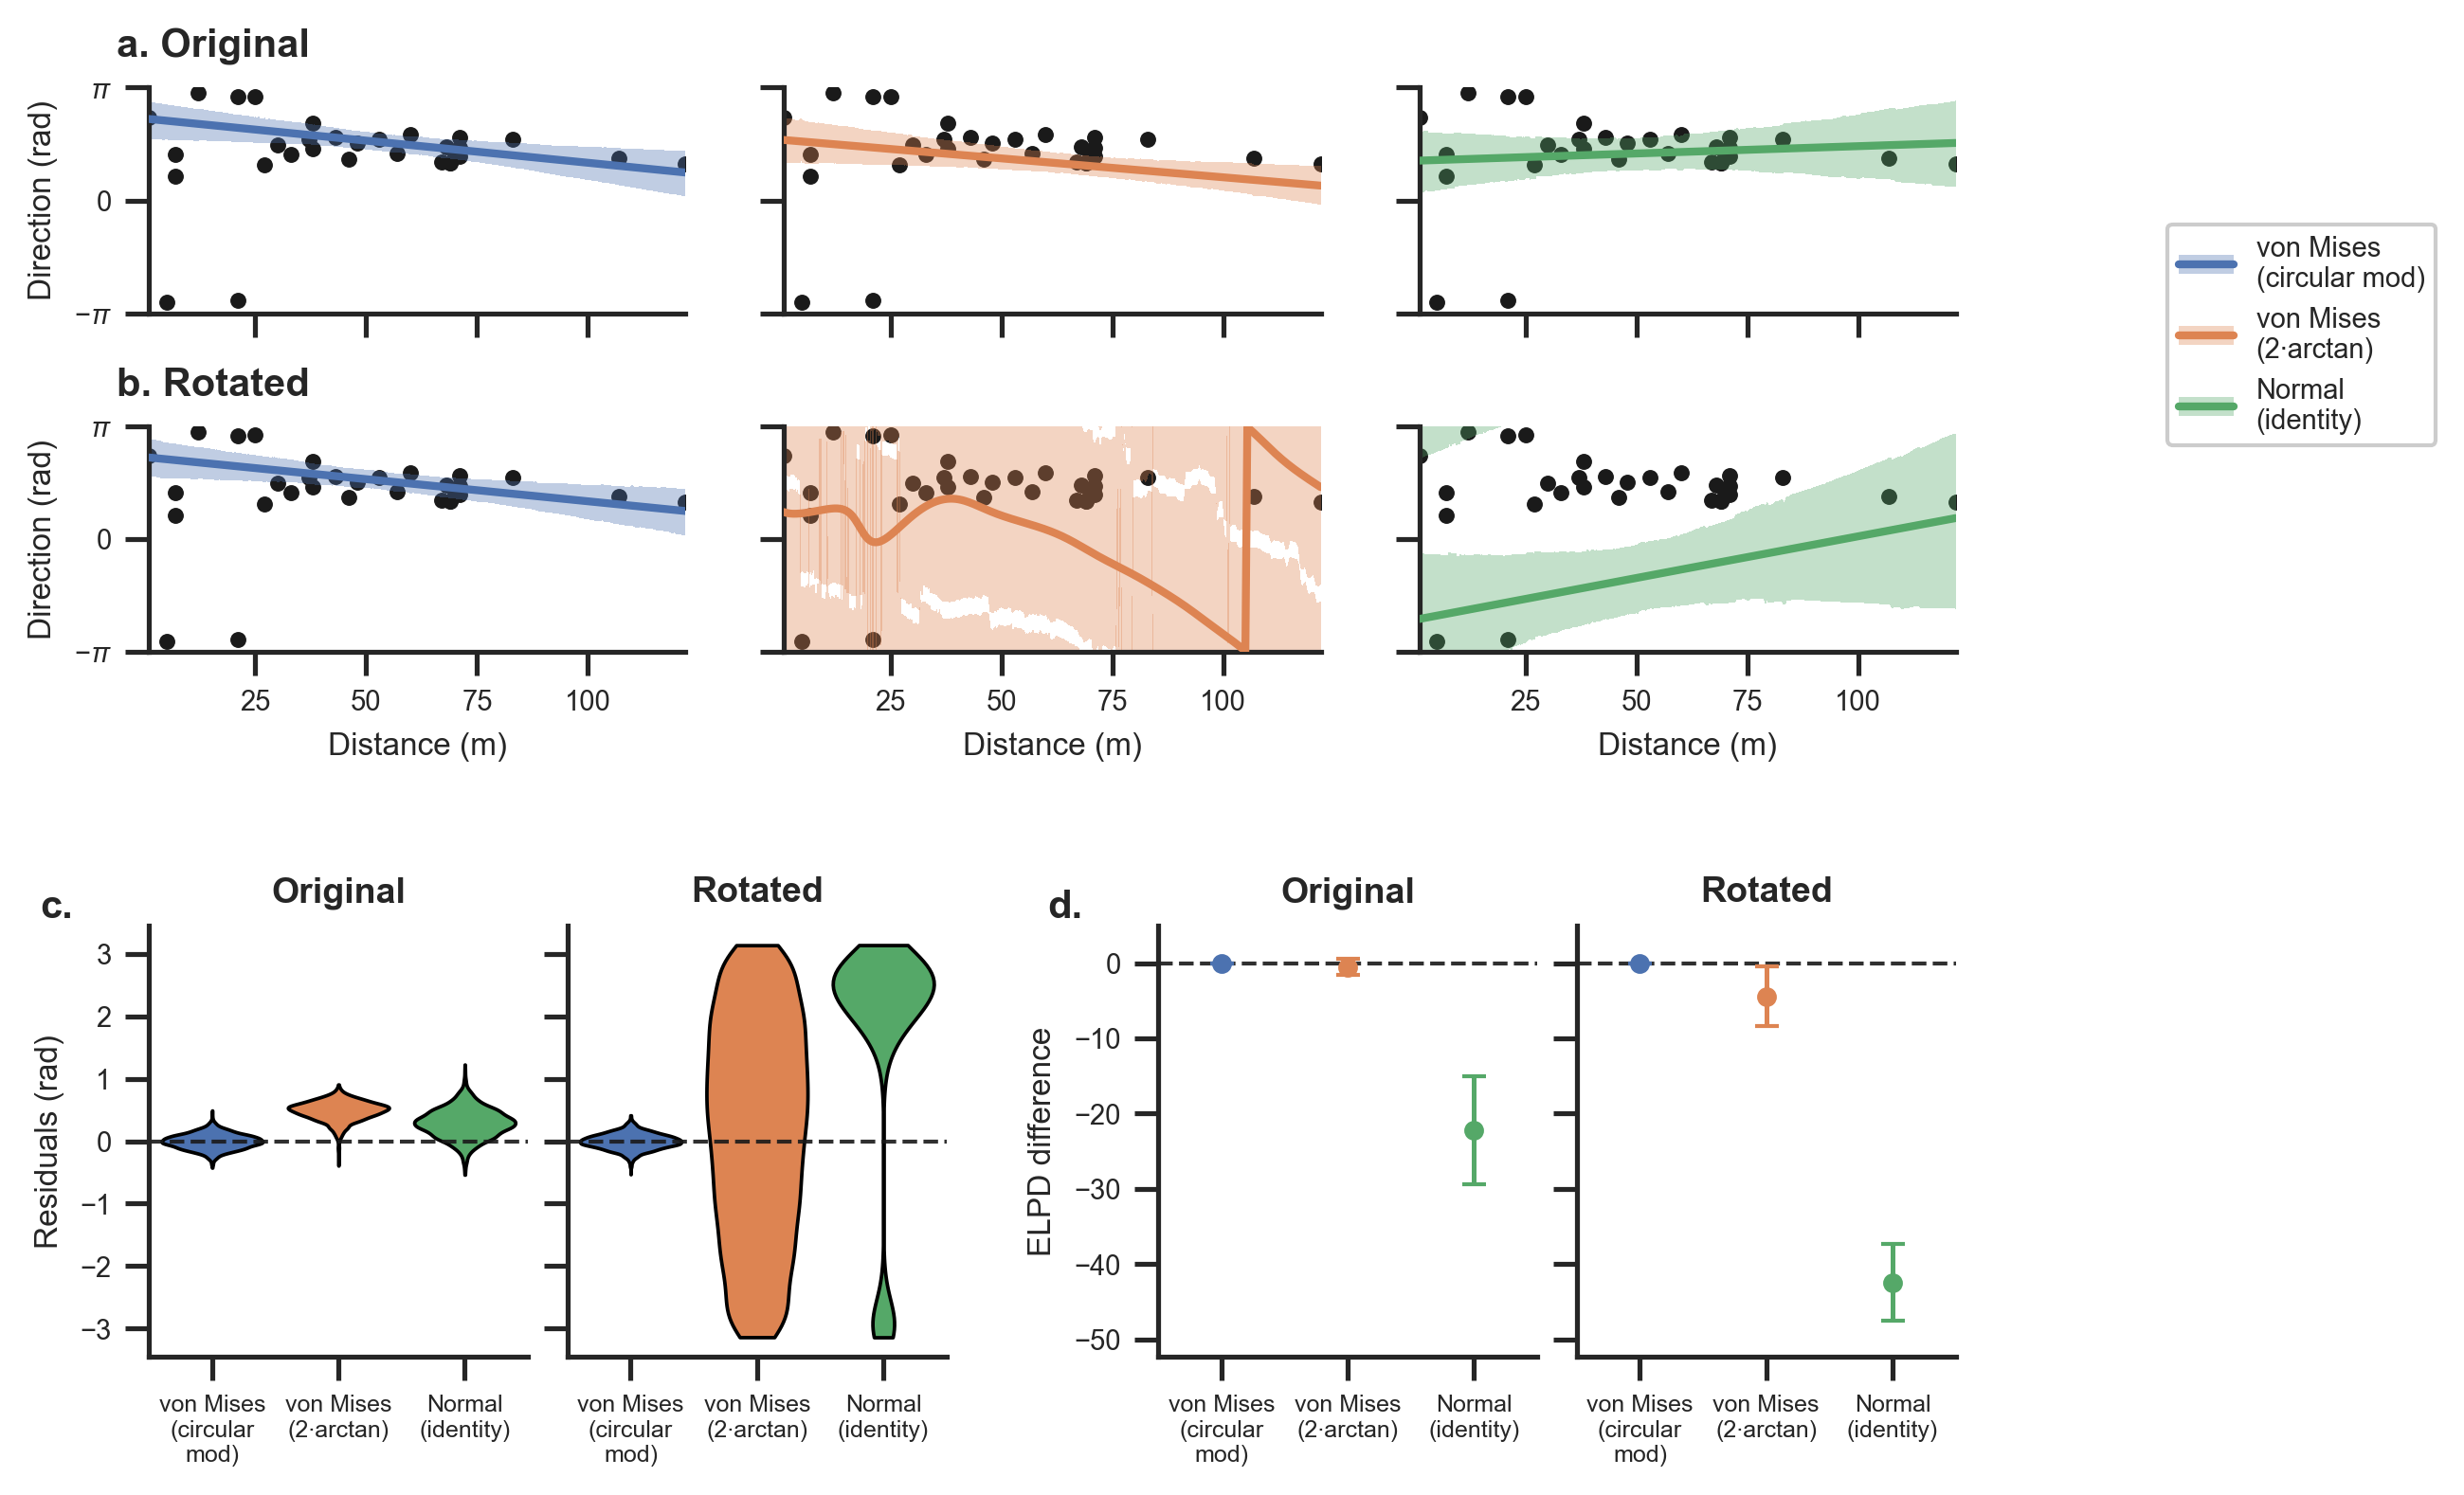

In [7]:
from pathlib import Path as PathlibPath
import warnings
# =========================
# Imports
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
import xarray as xr
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase
from matplotlib.patches import Rectangle
from matplotlib.path import Path
from matplotlib.patches import PathPatch
from matplotlib.gridspec import GridSpec

# =========================
# Global style: Arial + transparent backgrounds
# =========================
plt.rcParams.update({
    "font.family": "Arial",
    # Make mathtext match Arial-ish too
    "mathtext.fontset": "custom",
    "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic",
    "mathtext.bf": "Arial:bold",
})

sns.set_theme(style="white")  # keep clean seaborn defaults (we override transparency below)

# =========================
# Circular utils
# =========================
TAU = 2 * np.pi

def angle_wrap(a):
    """Wrap to (-pi, pi]."""
    return (np.asarray(a) + np.pi) % TAU - np.pi

def circ_mean_from_samples(samples, axis=0):
    """Circular mean along axis (radians)."""
    return np.angle(np.mean(np.exp(1j * samples), axis=axis))

# =========================
# Circular HDI (shortest arc)
# =========================
def _circular_hdi_1d(samples, prob=0.94):
    """
    Shortest-arc HDI for one x. samples in (-pi, pi].
    Returns (lo, hi, mu) also in (-pi, pi].
    """
    samp = np.asarray(samples, float)
    samp = samp[~np.isnan(samp)]
    if samp.size == 0:
        return np.nan, np.nan, np.nan

    mu = circ_mean_from_samples(samp, axis=0)
    centered = angle_wrap(samp - mu)
    s = np.sort(centered)
    n = s.size
    if n == 1:
        a = angle_wrap(s[0] + mu)
        return a, a, angle_wrap(mu)

    m = max(1, int(np.ceil(prob * n)))  # window size (count)
    s2 = np.concatenate([s, s + TAU])
    widths = s2[m:m+n] - s2[:n]
    j = np.argmin(widths)
    lo_rel = s2[j]
    hi_rel = s2[j + m]

    lo = angle_wrap(lo_rel + mu)
    hi = angle_wrap(hi_rel + mu)
    return lo, hi, angle_wrap(mu)

def circular_hdi(samples, prob=0.94, sample_axes=("chain", "draw")):
    """
    Vectorized circular HDI across x.
    samples: xarray (dims include sample_axes + 1 x dim) or numpy (C,D,X).
    Returns (lo, hi, mu) arrays of shape (X,).
    """
    if isinstance(samples, xr.DataArray):
        sample_axes = tuple(ax for ax in sample_axes if ax in samples.dims)
        xdims = [d for d in samples.dims if d not in sample_axes]
        if len(xdims) != 1:
            raise ValueError(f"Expected exactly one x dim; got {xdims} with dims={samples.dims}")
        xdim = xdims[0]
        da = samples.transpose(xdim, *sample_axes)          # (x, chain, draw)
        arr = da.stack(sample=sample_axes).values           # (X, N)
        X, _ = arr.shape
        lo = np.empty(X); hi = np.empty(X); mu = np.empty(X)
        for i in range(X):
            l, h, m = _circular_hdi_1d(arr[i, :], prob)
            lo[i], hi[i], mu[i] = l, h, m
        return lo, hi, mu

    arr = np.asarray(samples)
    if arr.ndim != 3:
        raise ValueError("Provide xarray with ('chain','draw', x) or numpy (chains, draws, X).")
    C, D, X = arr.shape
    flat = arr.reshape(C * D, X)
    lo = np.empty(X); hi = np.empty(X); mu = np.empty(X)
    for i in range(X):
        l, h, m = _circular_hdi_1d(flat[:, i], prob)
        lo[i], hi[i], mu[i] = l, h, m
    return lo, hi, mu

# =========================
# Main plotting helper: circular HDI band + mean line (seam-safe)
# =========================
def plot_circular_hdi(ax, x, samples, *, prob=0.94, color=None, alpha=0.25, zorder=2,
                      seam_tol=0.01, seam_pad=1):
    """
    Draw a seam-correct circular HDI band + mean line.
    - samples: xarray (chain, draw, x) or numpy (C,D,X), in radians.
    """
    x = np.asarray(x, float)

    lo, hi, mu = circular_hdi(samples, prob=prob)

    # unwrap band relative to mean so top ≥ bottom, then build one polygon
    mu_u = np.unwrap(mu)
    mu_w = angle_wrap(mu)
    lo_w = angle_wrap(lo)
    hi_w = angle_wrap(hi)
    d_lo = angle_wrap(lo_w - mu_w)
    d_hi = angle_wrap(hi_w - mu_w)
    lo_u = mu_u + d_lo
    hi_u = mu_u + d_hi
    flip = (hi_u - lo_u) < 0
    hi_u[flip] += 2 * np.pi

    xv = np.r_[x, x[::-1]]
    yv = np.r_[hi_u, lo_u[::-1]]
    verts = np.column_stack([xv, yv])

    # close polygon far outside Y so the closing edge is clipped away
    y_off = (hi_u.max() + lo_u.min()) / 2.0 + 10.0 * np.pi
    x0 = x[0]
    verts = np.vstack(([x0, y_off], [x0, yv[0]], verts, [x0, yv[-1]], [x0, y_off]))

    codes = np.full(len(verts), Path.LINETO, dtype=np.uint8)
    codes[0] = Path.MOVETO
    codes[-1] = Path.CLOSEPOLY

    # tile polygon in Y to cover [-π, π], clip to axes
    y_min = float(min(lo_u.min(), hi_u.min()))
    y_max = float(max(lo_u.max(), hi_u.max()))
    two_pi = 2 * np.pi
    k_min = int(np.ceil((-np.pi - y_max) / two_pi))
    k_max = int(np.floor(( np.pi - y_min) / two_pi))
    for k in range(k_min, k_max + 1):
        v = verts.copy()
        v[:, 1] = v[:, 1] + k * two_pi
        patch = PathPatch(
            Path(v, codes),
            facecolor=color, edgecolor="none",
            alpha=alpha, antialiased=False, zorder=zorder
        )
        patch.set_clip_path(ax.patch)
        ax.add_patch(patch)

    # mean line: hide near the ±π seam
    mu_line = angle_wrap(mu)
    dist_to_seam = np.pi - np.abs(mu_line)
    mask = dist_to_seam < seam_tol
    if seam_pad and np.any(mask):
        idx = np.where(mask)[0]
        for i in idx:
            a = max(0, i - seam_pad)
            b = min(len(mu_line), i + seam_pad + 1)
            mask[a:b] = True
    mu_line_masked = mu_line.copy()
    mu_line_masked[mask] = np.nan
    ax.plot(x, mu_line_masked, lw=2, color=color, zorder=zorder + 1)

    ax.set_ylim(-np.pi, np.pi)
    ax.set_yticks([-np.pi, 0, np.pi])
    ax.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
    return lo_w, hi_w, mu_w

# =========================
# Legend handler: line on top of fill
# =========================
class HandlerLineOnFill(HandlerBase):
    def create_artists(self, legend, orig_handle,
                       xdescent, ydescent, width, height, fontsize, trans):
        color, alpha, lw = orig_handle
        rect = Rectangle((xdescent, ydescent), width, height,
                         transform=trans, facecolor=color, edgecolor='none', alpha=alpha)
        y = ydescent + height / 2.0
        line = Line2D([xdescent, xdescent + width], [y, y],
                      transform=trans, color=color, lw=lw)
        return [rect, line]

# =========================
# Posterior residual bias helpers
# =========================
def wrap_circ(x):
    return np.arctan2(np.sin(x), np.cos(x))

def xr_circmean(da, dim, center=0.0):
    shifted = da - center
    s = xr.apply_ufunc(np.sin, shifted, dask="vectorized", output_dtypes=[float]).mean(dim)
    c = xr.apply_ufunc(np.cos, shifted, dask="vectorized", output_dtypes=[float]).mean(dim)
    mean_angle = xr.apply_ufunc(np.arctan2, s, c, dask="vectorized", output_dtypes=[float])
    return mean_angle + center

def infer_obs_dim(mu_da, n_obs):
    for d in mu_da.dims:
        if d not in ("chain", "draw") and mu_da.sizes[d] == n_obs:
            return d
    non_sample_dims = [d for d in mu_da.dims if d not in ("chain", "draw")]
    return non_sample_dims[-1] if non_sample_dims else mu_da.dims[-1]

def posterior_bias_per_draw(y_obs, mu_da):
    y_obs = np.asarray(y_obs)
    obs_dim = infer_obs_dim(mu_da, len(y_obs))
    y = xr.DataArray(y_obs, dims=[obs_dim])
    res = wrap_circ(y - mu_da)
    bias = xr_circmean(res, dim=obs_dim)
    if "chain" in bias.dims and "draw" in bias.dims:
        bias = bias.stack(sample=("chain", "draw"))
    elif "draw" in bias.dims:
        bias = bias.rename({"draw": "sample"})
    elif "chain" in bias.dims:
        bias = bias.rename({"chain": "sample"})
    return np.asarray(bias)

def biases_from_idatas(idatas, y_obs, deshift_mu_by=0.0):
    out = {}
    key2label = {
        "vm_shifted_mod_link": "von Mises\n(circular\nmod)",
        "vm_tan2":             "von Mises\n(2·arctan)",
        "gaussian":            "Normal\n(identity)",
    }
    for key, label in key2label.items():
        mu = idatas[key].posterior["mu"]
        if deshift_mu_by != 0.0:
            mu = mu - deshift_mu_by
        out[label] = posterior_bias_per_draw(y_obs, mu)
    return out

# =========================
# ELPD difference ± SE helpers
# =========================
def pointwise_elpd(idata):
    loo = az.loo(idata, pointwise=True)
    if hasattr(loo, "elpd_i"):
        arr = loo.elpd_i
    elif hasattr(loo, "loo_i"):
        arr = loo.loo_i
    else:
        raise AttributeError("Could not find pointwise ELPD in az.loo result.")
    return np.asarray(arr)

def elpd_diff_vs_best(idatas_dict):
    """
    Returns dict: label -> (diff_total, se_total), where diff is vs best model in this pipeline.
    diff_total = sum(elpd_i - elpd_best_i)
    se_total   = sqrt(n * var(elpd_i - elpd_best_i))
    """
    key2label = {
        "vm_shifted_mod_link": "von Mises\n(circular\nmod)",
        "vm_tan2":             "von Mises\n(2·arctan)",
        "gaussian":            "Normal\n(identity)",
    }
    elpds = {key2label[k]: pointwise_elpd(idatas_dict[k]) for k in key2label.keys()}
    totals = {lab: arr.sum() for lab, arr in elpds.items()}
    best_label = max(totals, key=totals.get)
    best_arr = elpds[best_label]
    n = best_arr.size

    out = {}
    for lab, arr in elpds.items():
        di = arr - best_arr
        diff_total = float(di.sum())
        # standard error of sum of pointwise differences:
        # SE(sum) = sqrt(n * var(di))
        if lab == best_label:
            se_total = 0.0
        else:
            se_total = float(np.sqrt(n * np.var(di, ddof=1)))
        out[lab] = (diff_total, se_total)
    return out, best_label

# =========================
# MULTIPANEL FIGURE (a,b,c,d) — assumes these already exist:
#   data, models_unshifted, idatas_unshifted, models_shifted, idatas_shifted
# =========================

# --- colors (match your earlier usage) ---
palette = sns.color_palette("deep", 3)
c0, c1, c2 = palette
model_labels = ["von Mises\n(circular\nmod)", "von Mises\n(2·arctan)", "Normal\n(identity)"]
model_colors = [c0, c1, c2]

# prediction grid (log space -> back to meters)
log_dist_grid = np.linspace(data.log_distance.min(), data.log_distance.max(), 1000)
dist_grid = np.expm1(log_dist_grid)
grid_df = pd.DataFrame({"distance": dist_grid, "log_distance": log_dist_grid})

def _plot_row(ax_row, *, models, idatas, scatter_y, deshift=0.0, row_title=""):
    # 1) von Mises (shifted modulo link)
    pred = models["vm_shifted_mod_link"].predict(idata=idatas["vm_shifted_mod_link"], data=grid_df, inplace=False)
    post0 = angle_wrap(pred.posterior["mu"] - deshift)
    plot_circular_hdi(ax_row[0], dist_grid, post0, prob=0.94, color=c0, alpha=0.35)
    sns.scatterplot(x=data.distance, y=angle_wrap(scatter_y - deshift),
                    ax=ax_row[0], s=14, color="k", edgecolor=None, alpha=1.0)

    # 2) von Mises (2·arctan link)
    pred = models["vm_tan2"].predict(idata=idatas["vm_tan2"], data=grid_df, inplace=False)
    post1 = angle_wrap(pred.posterior["mu"] - deshift)
    plot_circular_hdi(ax_row[1], dist_grid, post1, prob=0.94, color=c1, alpha=0.35)
    sns.scatterplot(x=data.distance, y=angle_wrap(scatter_y - deshift),
                    ax=ax_row[1], s=14, color="k", edgecolor=None, alpha=1.0)

    # 3) Normal baseline
    pred = models["gaussian"].predict(idata=idatas["gaussian"], data=grid_df, inplace=False)
    post2 = angle_wrap(pred.posterior["mu"] - deshift)
    plot_circular_hdi(ax_row[2], dist_grid, post2, prob=0.94, color=c2, alpha=0.35)
    sns.scatterplot(x=data.distance, y=angle_wrap(scatter_y - deshift),
                    ax=ax_row[2], s=14, color="k", edgecolor=None, alpha=1.0)

    # cosmetics
    for a in ax_row:
        a.set_xlim(dist_grid.min(), dist_grid.max())
        a.set_xlabel("")
        a.tick_params(axis="x", bottom=True, labelsize=7)
        a.tick_params(axis="y", left=True, labelsize=7)
    
    ax_row[0].set_ylabel("Direction (rad)", fontsize=8)
    for a in ax_row[1:]:
        a.set_ylabel("")
        a.tick_params(axis="y", left=True, labelleft=False)
    if row_title:
        ax_row[0].text(-0.06, 1.10, row_title, transform=ax_row[0].transAxes,
                       ha="left", va="bottom", fontsize=10, weight="bold")

# =========================
# Build single figure layout
# =========================
fig = plt.figure(figsize=(8.2, 5.8), dpi=300)

# transparent figure background
fig.patch.set_facecolor("none")
fig.patch.set_alpha(0)

# --- layout knobs ---
hspace_top = 0.5     # vertical gap between (a) and (b) rows
hspace_outer = 0.55   # gap between top block and bottom block
wspace_top = 0.45     # horizontal gap between top panels
wspace_pair = 0.12    # small gap within pairs (c1-c2) and (d1-d2)
pair_gap_ratio = 0.35 # spacer column width between c and d pairs (bigger => more gap)

# Outer grid: 2 rows (top block, bottom block) so we can control gaps independently
gs_outer = GridSpec(
    nrows=2, ncols=1, figure=fig,
    height_ratios=[1.70, 1.30],   # top vs bottom heights
    hspace=hspace_outer
)

# Top block: 2 rows x 6 cols (each panel spans 2 cols)
gs_top = gs_outer[0].subgridspec(
    nrows=2, ncols=6,
    hspace=hspace_top,
    wspace=wspace_top
)

ax_a1 = fig.add_subplot(gs_top[0, 0:2])
ax_a2 = fig.add_subplot(gs_top[0, 2:4], sharex=ax_a1, sharey=ax_a1)
ax_a3 = fig.add_subplot(gs_top[0, 4:6], sharex=ax_a1, sharey=ax_a1)

ax_b1 = fig.add_subplot(gs_top[1, 0:2], sharex=ax_a1, sharey=ax_a1)
ax_b2 = fig.add_subplot(gs_top[1, 2:4], sharex=ax_a1, sharey=ax_a1)
ax_b3 = fig.add_subplot(gs_top[1, 4:6], sharex=ax_a1, sharey=ax_a1)

top_axes = [[ax_a1, ax_a2, ax_a3], [ax_b1, ax_b2, ax_b3]]

# Bottom block: 1 row x 5 cols, with a spacer col in the middle to keep a big c-vs-d gap
gs_bot = gs_outer[1].subgridspec(
    nrows=1, ncols=5,
    width_ratios=[1, 1, pair_gap_ratio, 1, 1],
    wspace=wspace_pair
)

ax_c1 = fig.add_subplot(gs_bot[0, 0])
ax_c2 = fig.add_subplot(gs_bot[0, 1], sharey=ax_c1)
ax_d1 = fig.add_subplot(gs_bot[0, 3])
ax_d2 = fig.add_subplot(gs_bot[0, 4], sharey=ax_d1)

# Make all axes transparent
for ax in [ax_a1, ax_a2, ax_a3, ax_b1, ax_b2, ax_b3, ax_c1, ax_c2, ax_d1, ax_d2]:
    ax.set_facecolor("none")
    ax.patch.set_facecolor("none")
    ax.patch.set_alpha(0)

# =========================
# (a) Original row
# =========================
_plot_row(
    top_axes[0],
    models=models_unshifted,
    idatas=idatas_unshifted,
    scatter_y=data["direction_unshifted"].to_numpy(),
    deshift=0.0,
    row_title="a. Original"
)

# =========================
# (b) Rotated row (de-shift display by π/2)
# =========================
_plot_row(
    top_axes[1],
    models=models_shifted,
    idatas=idatas_shifted,
    scatter_y=data["direction_shifted"].to_numpy(),
    deshift=np.pi/2,
    row_title="b. Rotated"
)

# x-axis labels only on the second row (like the reference)
for ax in top_axes[1]:
    ax.set_xlabel("Distance (m)", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in top_axes[0]:
    ax.tick_params(axis="x", bottom=True, labelbottom=False, labelsize=7)

# =========================
# Shared legend (right of the top panels)
# =========================
legend_labels = ["von Mises\n(circular mod)", "von Mises\n(2·arctan)", "Normal\n(identity)"]
legend_handles = [(c0, 0.35, 2), (c1, 0.35, 2), (c2, 0.35, 2)]
leg = fig.legend(
    legend_handles, legend_labels,
    handler_map={tuple: HandlerLineOnFill()},
    loc="center left", bbox_to_anchor=(0.985, 0.73),
    frameon=True, title="", fontsize=7
)
leg.get_frame().set_facecolor("none")
leg.get_frame().set_alpha(1.0)

# =========================
# (c) Posterior residual bias (violin) — Original vs Rotated
# =========================
bias_left = biases_from_idatas(
    idatas_unshifted,
    y_obs=np.asarray(data["direction_unshifted"]),
    deshift_mu_by=0.0
)
bias_right = biases_from_idatas(
    idatas_shifted,
    y_obs=np.asarray(data["direction_unshifted"]),
    deshift_mu_by=np.pi/2
)

def to_df_bias(bias_dict, pipeline_label):
    labs = list(bias_dict.keys())
    return pd.DataFrame({
        "bias": np.concatenate([bias_dict[labs[0]], bias_dict[labs[1]], bias_dict[labs[2]]]),
        "model": ([labs[0]] * len(bias_dict[labs[0]])
                  + [labs[1]] * len(bias_dict[labs[1]])
                  + [labs[2]] * len(bias_dict[labs[2]])),
        "pipeline": pipeline_label,
    })

df_bias = pd.concat([to_df_bias(bias_left, "Original"),
                     to_df_bias(bias_right, "Rotated")], ignore_index=True)

violin_palette = {
    model_labels[0]: c0,
    model_labels[1]: c1,
    model_labels[2]: c2,
}

for ax, pipe, title in [(ax_c1, "Original", "Original"), (ax_c2, "Rotated", "Rotated")]:
    d = df_bias[df_bias["pipeline"] == pipe].copy()

    vp = sns.violinplot(
        data=d, x="model", y="bias",
        order=model_labels, ax=ax, hue="model", legend=False,
        palette=violin_palette,
        saturation=1,
        linewidth=0.9,
        inner=None,      # <-- no interior box/anything
        cut=0
    )

    # black outlines
    for coll in ax.collections:
        coll.set_edgecolor("black")
        coll.set_linewidth(0.9)

    ax.axhline(0, ls="--", lw=1, color="k", alpha=0.9)
    ax.set_title(title, fontsize=9, weight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", bottom=True, labelsize=6)
    ax.tick_params(axis="y", left=True, labelsize=7)

ax_c1.set_ylabel("Residuals (rad)", fontsize=8)
ax_c2.set_ylabel("")
ax_c2.tick_params(axis="y", left=True, labelleft=False)
ax_c1.text(-0.2, 1.0, "c.", transform=ax_c1.transAxes,
           ha="right", va="bottom", fontsize=10, weight="bold")

# =========================
# (d) ELPD difference ± SE (standard) — Original vs Rotated
# =========================
diff_left, best_left = elpd_diff_vs_best(idatas_unshifted)
diff_right, best_right = elpd_diff_vs_best(idatas_shifted)

def plot_elpd_diff(ax, diff_dict, title):
    xs = np.arange(len(model_labels))
    diffs = np.array([diff_dict[lab][0] for lab in model_labels], float)
    ses   = np.array([diff_dict[lab][1] for lab in model_labels], float)

    ax.axhline(0, ls="--", lw=1, color="k", alpha=0.9)
    for i, (lab, col) in enumerate(zip(model_labels, model_colors)):
        ax.errorbar(xs[i], diffs[i], yerr=ses[i], fmt="o",
                    color=col, ecolor=col, elinewidth=1.2, capsize=3,
                    markersize=4, zorder=3)

    ax.set_xticks(xs)
    ax.set_xlim(-0.5, 2.5)
    ax.set_xticklabels(model_labels, fontsize=7)
    ax.set_title(title, fontsize=9, weight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="y", labelsize=7)
    ax.tick_params(axis="x", labelsize=6)

    # Make 0 near the top like typical ΔELPD plots
    ymin = np.min(diffs - ses)
    ax.set_ylim(ymin - 0.1 * abs(ymin), 5)

plot_elpd_diff(ax_d1, diff_left,  "Original")
plot_elpd_diff(ax_d2, diff_right, "Rotated")

ax_d1.set_ylabel("ELPD difference", fontsize=8)
ax_d2.set_ylabel("")
ax_d1.text(-0.2, 1.0, "d.", transform=ax_d1.transAxes,
           ha="right", va="bottom", fontsize=10, weight="bold")
# left (d1): keep y tick labels
ax_d1.tick_params(axis="y", left=True, labelleft=True, labelsize=7)
ax_d1.tick_params(axis="x", bottom=True, labelbottom=True, labelsize=6)

# right (d2): keep y tick marks, hide y tick labels (so you still see tick positions)
ax_d2.tick_params(axis="y", left=True, labelleft=False, labelsize=7)
ax_d2.tick_params(axis="x", bottom=True, labelbottom=True, labelsize=6)

# =========================
# Final cosmetics + save (transparent)
# =========================
sns.despine(fig=fig)
# GridSpec axes are not tight_layout compatible; layout is the
# original figure layout, only the cosmetic warning is scoped out.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=r".*not compatible with tight_layout.*")
    fig.tight_layout(rect=[0.0, 0.0, 0.92, 1.0])

PathlibPath("figures").mkdir(exist_ok=True)
plt.savefig("./figures/periwinkles_multipanel.pdf", bbox_inches="tight", transparent=True)
plt.show()

## Output files

| file | contents |
|---|---|
| `figures/periwinkles_multipanel.pdf` | the supplement figure (a-d) |
| `figures/periwinkles_rotation_lines.pdf` | (a-b) fitted-mean rows |
| `figures/periwinkles_rotation_residuals.pdf` | (c) residual-bias violins |
| `figures/periwinkles_rotation_elpd.pdf` | per-observation ELPD violins |

(The PNG previews embedded above are notebook renders, not artifacts.)